# WEEK 7 – DIMENSIONALITY REDUCTION

## Project: Netflix Viewing Pattern Analysis

### Introduction

In Week 7, we focus on **Dimensionality Reduction**, which is an important step in the data science workflow. The main objective is to reduce the number of numerical features in the dataset while preserving as much useful information as possible.

We will use the feature-engineered Netflix dataset obtained from Week 6 and perform feature selection and Principal Component Analysis (PCA).

### Objectives

1. Perform correlation analysis using a correlation matrix.
2. Identify and remove highly correlated features to reduce multicollinearity.
3. Apply StandardScaler to standardise the numerical features.
4. Implement Principal Component Analysis (PCA).
5. Calculate and visualise the Explained Variance Ratio.
6. Create 2D and 3D scatter plots using Principal Components.
7. Generate and save the final reduced dataset for further analysis.

### Dataset Used

**Input Dataset:** `netflix_week6_feature_engineered.csv`

This dataset contains the features created through data cleaning, transformation, encoding, and feature engineering during Week 6.

### Expected Outcome

By the end of Week 7, we aim to obtain a reduced dataset containing principal components instead of the original numerical features. We will also analyse how much variance is retained after dimensionality reduction.

The final PCA dataset will be used in **Week 8 – Dashboard Construction**.

### Tools and Libraries

- Python
- Pandas and NumPy
- Matplotlib and Seaborn
- Scikit-learn

### Workflow

Dataset Loading → Correlation Analysis → Feature Selection → Feature Scaling → PCA Implementation → Explained Variance Visualisation → 2D/3D PCA Visualisation → Export Reduced Dataset



## 1. Import Libraries

We import the required Python libraries for data manipulation, visualisation, feature scaling, and Principal Component Analysis.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

import warnings
warnings.filterwarnings("ignore")

print("Libraries imported successfully!")

Libraries imported successfully!


## 2. Load the Week 6 Dataset

The Week 6 feature-engineered dataset is used as input for Week 7.
We inspect the dataset to understand its structure, dimensions,
column names, and data types.

In [3]:
week6_file = "netflix_week6_feature_engineered.csv"

if not os.path.exists(week6_file):
    raise FileNotFoundError(
        "Please place netflix_week6_feature_engineered.csv "
        "in the same folder as this notebook."
    )

df = pd.read_csv(week6_file)

print("Dataset loaded successfully!")
print("Dataset Shape:", df.shape)

display(df.head())
print(df.info())

Dataset loaded successfully!
Dataset Shape: (8807, 33)


,release_year,added_year,movie_duration_min,tv_seasons,type_Movie,type_TV Show,rating_66 min,rating_74 min,rating_84 min,rating_G,...,genre_International Movies,genre_Dramas,genre_Comedies,genre_International TV Shows,genre_Documentaries,genre_Action & Adventure,genre_TV Dramas,genre_Independent Movies,genre_Children & Family Movies,genre_Romantic Movies
0,5.030862,2.38331,84.264815,0.000000,1,0,0,0,0,0,...,0,0,0,0,1,0,0,0,0,0
1,7.427335,2.38331,0.000000,0.307536,0,1,0,0,0,0,...,0,0,0,1,0,0,1,0,0,0
2,7.427335,2.38331,0.000000,0.281732,0,1,0,0,0,0,...,0,0,0,1,0,0,0,0,0,0
3,7.427335,2.38331,0.000000,0.281732,0,1,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,7.427335,2.38331,0.000000,0.307536,0,1,0,0,0,0,...,0,0,0,1,0,0,0,0,0,0


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8807 entries, 0 to 8806
Data columns (total 33 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   release_year                    8807 non-null   float64
 1   added_year                      8807 non-null   float64
 2   movie_duration_min              8807 non-null   float64
 3   tv_seasons                      8807 non-null   float64
 4   type_Movie                      8807 non-null   int64  
 5   type_TV Show                    8807 non-null   int64  
 6   rating_66 min                   8807 non-null   int64  
 7   rating_74 min                   8807 non-null   int64  
 8   rating_84 min                   8807 non-null   int64  
 9   rating_G                        8807 non-null   int64  
 10  rating_NC-17                    8807 non-null   int64  
 11  rating_NR                       8807 non-null   int64  
 12  rating_PG                       88

## 3. Select Numerical Features

Correlation analysis and PCA require numerical data.
Therefore, we select only numerical columns and remove
constant columns because they do not contain useful variation.

In [4]:
numeric_df = df.select_dtypes(include=np.number).copy()

constant_columns = [
    col for col in numeric_df.columns
    if numeric_df[col].nunique() <= 1
]

numeric_df.drop(columns=constant_columns, inplace=True)

print("Numerical features:", numeric_df.shape[1])
print("Removed constant columns:", constant_columns)

display(numeric_df.head())

Numerical features: 33
Removed constant columns: []


,release_year,added_year,movie_duration_min,tv_seasons,type_Movie,type_TV Show,rating_66 min,rating_74 min,rating_84 min,rating_G,...,genre_International Movies,genre_Dramas,genre_Comedies,genre_International TV Shows,genre_Documentaries,genre_Action & Adventure,genre_TV Dramas,genre_Independent Movies,genre_Children & Family Movies,genre_Romantic Movies
0,5.030862,2.38331,84.264815,0.000000,1,0,0,0,0,0,...,0,0,0,0,1,0,0,0,0,0
1,7.427335,2.38331,0.000000,0.307536,0,1,0,0,0,0,...,0,0,0,1,0,0,1,0,0,0
2,7.427335,2.38331,0.000000,0.281732,0,1,0,0,0,0,...,0,0,0,1,0,0,0,0,0,0
3,7.427335,2.38331,0.000000,0.281732,0,1,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,7.427335,2.38331,0.000000,0.307536,0,1,0,0,0,0,...,0,0,0,1,0,0,0,0,0,0


## 4. Check Missing and Infinite Values

PCA cannot process missing or infinite values.
We check the numerical dataset before applying PCA.
If any such values exist, they should be corrected in Week 6.

In [5]:
missing_count = numeric_df.isnull().sum().sum()

infinite_count = np.isinf(
    numeric_df.to_numpy(dtype=float)
).sum()

print("Missing values:", missing_count)
print("Infinite values:", infinite_count)

if missing_count > 0 or infinite_count > 0:
    raise ValueError(
        "Please correct missing or infinite values before PCA."
    )

Missing values: 0
Infinite values: 0


## 5. Correlation Matrix Analysis

A correlation matrix identifies relationships between numerical
features.

Correlation values range from -1 to +1:
- +1 indicates a perfect positive correlation.
- -1 indicates a perfect negative correlation.
- 0 indicates no linear correlation.

A heatmap is used to visualise these relationships.

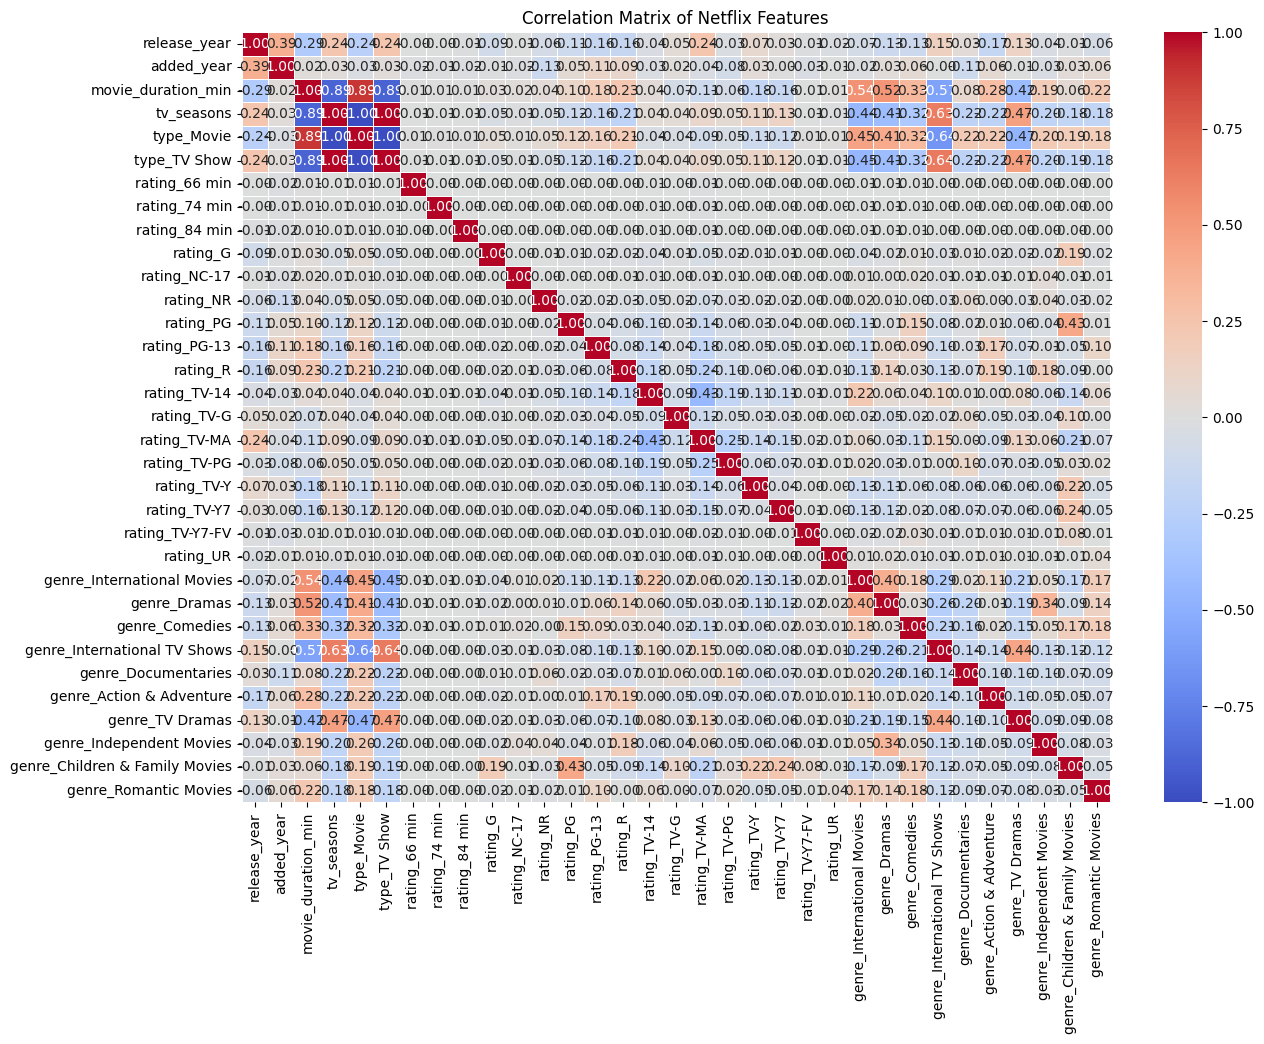

In [6]:
correlation_matrix = numeric_df.corr()

plt.figure(figsize=(14, 10))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Matrix of Netflix Features")
plt.show()

## 6. Feature Selection Using Correlation

Highly correlated features may contain redundant information.

We use an absolute correlation threshold of 0.90.
If two features have a correlation greater than 0.90
or less than -0.90, one feature is removed.

This helps reduce multicollinearity.

In [7]:
correlation_threshold = 0.90

upper_triangle = correlation_matrix.where(
    np.triu(
        np.ones(correlation_matrix.shape),
        k=1
    ).astype(bool)
)

high_correlation_features = [
    column
    for column in upper_triangle.columns
    if any(
        upper_triangle[column].abs() > correlation_threshold
    )
]

selected_df = numeric_df.drop(
    columns=high_correlation_features
)

print("Original feature count:", numeric_df.shape[1])
print("Removed features:", high_correlation_features)
print("Selected feature count:", selected_df.shape[1])

display(selected_df.head())

Original feature count: 33
Removed features: ['type_Movie', 'type_TV Show']
Selected feature count: 31


,release_year,added_year,movie_duration_min,tv_seasons,rating_66 min,rating_74 min,rating_84 min,rating_G,rating_NC-17,rating_NR,...,genre_International Movies,genre_Dramas,genre_Comedies,genre_International TV Shows,genre_Documentaries,genre_Action & Adventure,genre_TV Dramas,genre_Independent Movies,genre_Children & Family Movies,genre_Romantic Movies
0,5.030862,2.38331,84.264815,0.000000,0,0,0,0,0,0,...,0,0,0,0,1,0,0,0,0,0
1,7.427335,2.38331,0.000000,0.307536,0,0,0,0,0,0,...,0,0,0,1,0,0,1,0,0,0
2,7.427335,2.38331,0.000000,0.281732,0,0,0,0,0,0,...,0,0,0,1,0,0,0,0,0,0
3,7.427335,2.38331,0.000000,0.281732,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,7.427335,2.38331,0.000000,0.307536,0,0,0,0,0,0,...,0,0,0,1,0,0,0,0,0,0


## 7. Feature Scaling Using StandardScaler

PCA is sensitive to the scale of numerical features.

StandardScaler transforms the features so that they have
approximately:
- Mean = 0
- Standard deviation = 1

This ensures that features are on a comparable scale
before applying PCA.

In [8]:
scaler = StandardScaler()

scaled_array = scaler.fit_transform(selected_df)

scaled_df = pd.DataFrame(
    scaled_array,
    columns=selected_df.columns
)

print("Standardisation completed successfully!")

display(scaled_df.head())

Standardisation completed successfully!


,release_year,added_year,movie_duration_min,tv_seasons,rating_66 min,rating_74 min,rating_84 min,rating_G,rating_NC-17,rating_NR,...,genre_International Movies,genre_Dramas,genre_Comedies,genre_International TV Shows,genre_Documentaries,genre_Action & Adventure,genre_TV Dramas,genre_Independent Movies,genre_Children & Family Movies,genre_Romantic Movies
0,1.290870,1.535004,0.407228,-0.659543,-0.010656,-0.010656,-0.010656,-0.06839,-0.01846,-0.095744,...,-0.674166,-0.616772,-0.484442,-0.425672,3.022356,-0.328751,-0.307983,-0.306433,-0.280172,-0.274234
1,1.926734,1.535004,-1.350050,1.630178,-0.010656,-0.010656,-0.010656,-0.06839,-0.01846,-0.095744,...,-0.674166,-0.616772,-0.484442,2.349229,-0.330868,-0.328751,3.246936,-0.306433,-0.280172,-0.274234
2,1.926734,1.535004,-1.350050,1.438054,-0.010656,-0.010656,-0.010656,-0.06839,-0.01846,-0.095744,...,-0.674166,-0.616772,-0.484442,2.349229,-0.330868,-0.328751,-0.307983,-0.306433,-0.280172,-0.274234
3,1.926734,1.535004,-1.350050,1.438054,-0.010656,-0.010656,-0.010656,-0.06839,-0.01846,-0.095744,...,-0.674166,-0.616772,-0.484442,-0.425672,-0.330868,-0.328751,-0.307983,-0.306433,-0.280172,-0.274234
4,1.926734,1.535004,-1.350050,1.630178,-0.010656,-0.010656,-0.010656,-0.06839,-0.01846,-0.095744,...,-0.674166,-0.616772,-0.484442,2.349229,-0.330868,-0.328751,-0.307983,-0.306433,-0.280172,-0.274234


## 8. Principal Component Analysis (PCA)

Principal Component Analysis is a dimensionality reduction
technique used to reduce the number of numerical features.

PCA creates new variables called Principal Components.

- PC1 captures the maximum possible variance.
- PC2 captures the next highest variance.
- PC3 captures the next highest variance.

We first apply PCA using all available components.

In [9]:
pca_all = PCA()

pca_all_array = pca_all.fit_transform(scaled_df)

explained_variance = pca_all.explained_variance_ratio_

cumulative_variance = np.cumsum(explained_variance)

print("Explained Variance Ratio:")
print(explained_variance)

print("\nCumulative Explained Variance:")
print(cumulative_variance)

Explained Variance Ratio:
[1.24502841e-01 6.41989178e-02 5.03197707e-02 4.85870305e-02
 4.72213976e-02 4.22409670e-02 3.99242178e-02 3.71305435e-02
 3.51251258e-02 3.36158896e-02 3.34543921e-02 3.28278707e-02
 3.25601566e-02 3.24341508e-02 3.23101827e-02 3.22625277e-02
 3.22617750e-02 3.21930545e-02 3.02508022e-02 2.97611467e-02
 2.93227982e-02 2.58003187e-02 2.08381000e-02 1.96855351e-02
 1.58629006e-02 1.44481416e-02 1.14390836e-02 1.05797510e-02
 6.41184720e-03 2.42876310e-03 5.60755358e-17]

Cumulative Explained Variance:
[0.12450284 0.18870176 0.23902153 0.28760856 0.33482996 0.37707092
 0.41699514 0.45412569 0.48925081 0.5228667  0.55632109 0.58914896
 0.62170912 0.65414327 0.68645345 0.71871598 0.75097776 0.78317081
 0.81342161 0.84318276 0.87250556 0.89830588 0.91914398 0.93882951
 0.95469241 0.96914056 0.98057964 0.99115939 0.99757124 1.
 1.        ]


## 9. Explained Variance Visualisation

The explained variance ratio shows how much information
each principal component captures.

The cumulative explained variance shows the total variance
retained as more components are included.

We use two plots:
1. Scree Plot
2. Cumulative Explained Variance Plot

The 90% line represents our target variance.

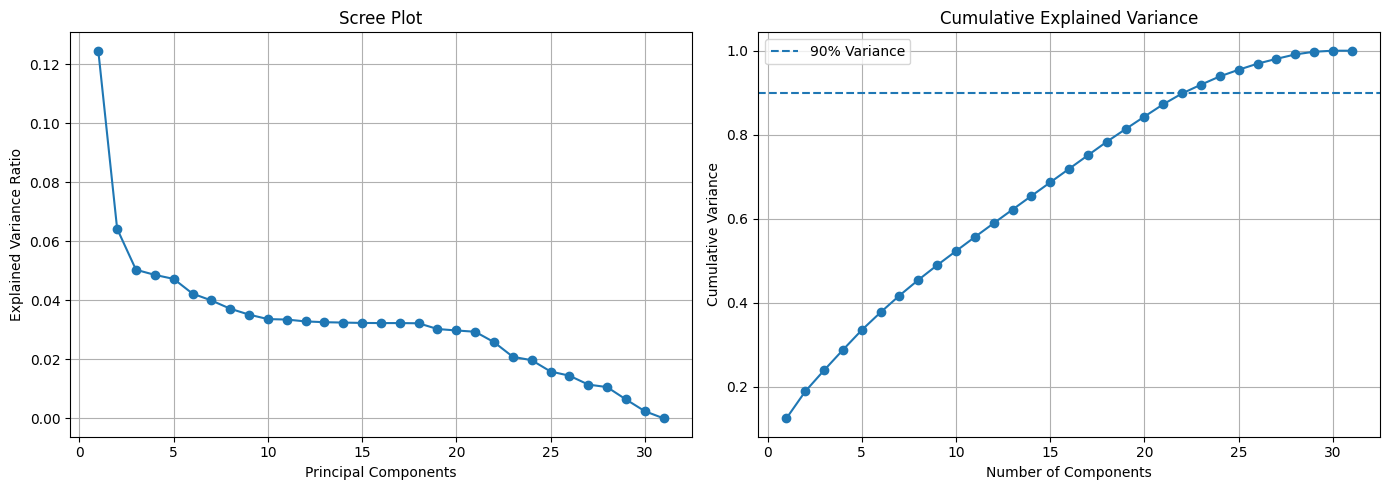

In [10]:
component_numbers = np.arange(
    1, len(explained_variance) + 1
)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Scree Plot
axes[0].plot(
    component_numbers,
    explained_variance,
    marker="o"
)

axes[0].set_title("Scree Plot")
axes[0].set_xlabel("Principal Components")
axes[0].set_ylabel("Explained Variance Ratio")
axes[0].grid(True)

# Cumulative Variance Plot
axes[1].plot(
    component_numbers,
    cumulative_variance,
    marker="o"
)

axes[1].axhline(
    y=0.90,
    linestyle="--",
    label="90% Variance"
)

axes[1].set_title("Cumulative Explained Variance")
axes[1].set_xlabel("Number of Components")
axes[1].set_ylabel("Cumulative Variance")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()

## 10. Selecting Principal Components

We select the minimum number of principal components
required to retain at least 90% of the total variance.

If 90% cannot be achieved, we report the maximum
variance retained by the available components.

In [11]:
variance_target = 0.90

components_reaching_target = np.where(
    cumulative_variance >= variance_target
)[0]

if len(components_reaching_target) > 0:
    n_components = int(
        components_reaching_target[0] + 1
    )
else:
    n_components = len(explained_variance)

print("Selected Components:", n_components)

print(
    "Variance Retained:",
    round(cumulative_variance[n_components - 1] * 100, 2),
    "%"
)

Selected Components: 23
Variance Retained: 91.91 %


## 11. Create Reduced PCA Dataset

We apply PCA again using the selected number of components.

The original numerical features are transformed into
a smaller set of principal components.

This creates a reduced dataset while retaining
the selected amount of variance.

In [12]:
pca_final = PCA(n_components=n_components)

pca_final_array = pca_final.fit_transform(scaled_df)

pca_columns = [
    f"PC{i+1}" for i in range(n_components)
]

pca_final_df = pd.DataFrame(
    pca_final_array,
    columns=pca_columns
)

print("Reduced Dataset Shape:", pca_final_df.shape)

display(pca_final_df.head())

Reduced Dataset Shape: (8807, 23)


,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8,PC9,PC10,...,PC14,PC15,PC16,PC17,PC18,PC19,PC20,PC21,PC22,PC23
0,0.432668,0.641924,-0.539949,0.506408,0.074497,3.900604,1.045824,0.524243,0.354090,0.940143,...,-0.056478,-0.053323,-0.025486,0.009141,-0.260667,2.323873,-2.405642,0.016114,0.301965,0.573931
1,-4.341283,-1.275748,-1.533891,-1.136394,-0.722373,-0.041518,0.971394,-0.130218,-0.913295,0.091953,...,-0.053437,-0.051227,-0.019484,-0.002589,0.000412,0.897404,0.406877,-0.393688,-0.192409,1.596404
2,-3.245220,-0.781848,-1.813712,-0.478167,-0.760111,0.541194,0.329889,-0.055371,-0.350930,-0.065054,...,-0.010979,-0.021768,-0.003401,-0.000872,0.018108,0.652510,0.381495,-0.230991,-0.036478,-1.276566
3,-2.258199,-0.389459,-2.099522,0.017673,-0.803823,0.936226,-0.073506,-0.124591,0.091342,-0.150595,...,0.001147,-0.003400,0.005358,-0.000069,0.035484,0.543804,0.342290,-0.050214,-0.008405,-0.932242
4,-3.333336,-0.789272,-1.800955,-0.505839,-0.755482,0.530790,0.318992,-0.038565,-0.341061,-0.064966,...,-0.011370,-0.024179,-0.003207,-0.000829,0.017468,0.640809,0.389189,-0.241620,-0.039801,-1.309648


## 12. Prepare Content Type Labels

We prepare Movie and TV Show labels to colour the PCA
scatter plots.

The raw Netflix dataset is used only if its row count
matches the Week 6 dataset. This assumes that the original
row order was preserved.

In [13]:
content_types = None

raw_file = "netflix_titles.csv"

if os.path.exists(raw_file):
    raw_df = pd.read_csv(raw_file)

    if len(raw_df) == len(df) and "type" in raw_df.columns:
        content_types = raw_df["type"].reset_index(drop=True)

if content_types is None:
    type_columns = [
        col for col in df.columns
        if col.lower() in ["type_movie", "type_tv show",
                           "type_tv_show", "type_tv"]
    ]

    if type_columns:
        type_data = df[type_columns].reset_index(drop=True)

        content_types = type_data.idxmax(axis=1).str.replace(
            "type_", "", regex=False
        )

print("Content labels available:", content_types is not None)

Content labels available: True


## 13. Two-Dimensional PCA Visualisation

The 2D scatter plot uses the first two principal components:
PC1 and PC2.

Each point represents a Netflix title.
Different colours represent Movie and TV Show categories
when matching labels are available.

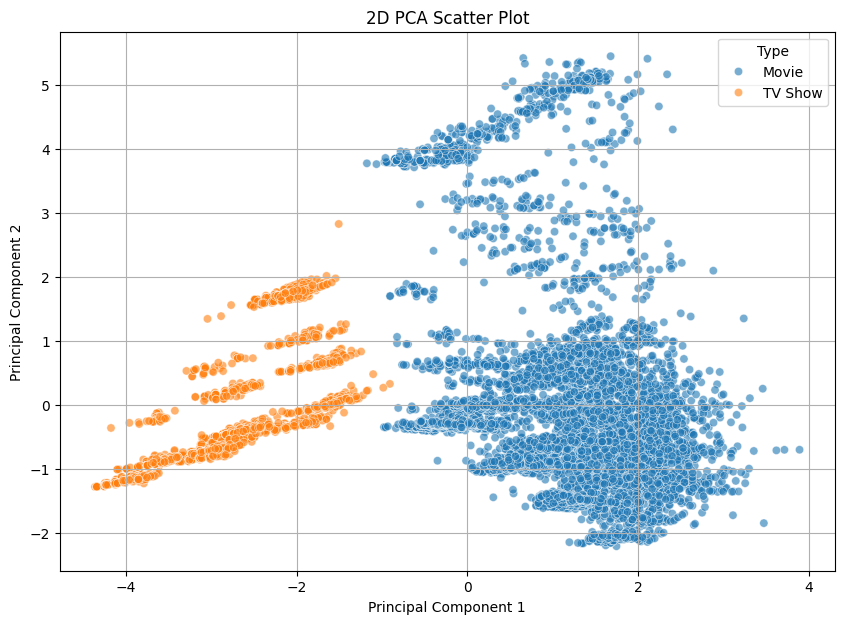

In [14]:
if pca_final_df.shape[1] >= 2:

    plt.figure(figsize=(10, 7))

    if content_types is not None:
        plot_df = pca_final_df[["PC1", "PC2"]].copy()
        plot_df["Type"] = content_types.values

        sns.scatterplot(
            data=plot_df,
            x="PC1",
            y="PC2",
            hue="Type",
            alpha=0.6
        )

    else:
        plt.scatter(
            pca_final_df["PC1"],
            pca_final_df["PC2"],
            alpha=0.6
        )

    plt.title("2D PCA Scatter Plot")
    plt.xlabel("Principal Component 1")
    plt.ylabel("Principal Component 2")
    plt.grid(True)
    plt.show()

else:
    print("Not enough components for a 2D plot.")

## 14. Three-Dimensional PCA Visualisation

The 3D scatter plot uses PC1, PC2, and PC3.

It provides a three-dimensional view of the reduced
feature space.

This plot is generated only when at least three
principal components are available.

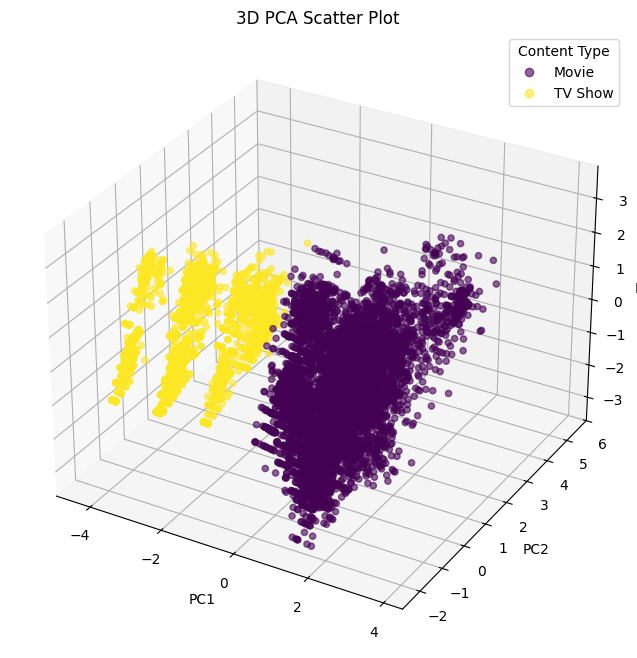

In [16]:
if pca_final_df.shape[1] >= 3:

    from mpl_toolkits.mplot3d import Axes3D

    fig = plt.figure(figsize=(10, 8))

    ax = fig.add_subplot(111, projection="3d")

    if content_types is not None:
        categories = pd.Categorical(content_types)

        scatter = ax.scatter(
            pca_final_df["PC1"],
            pca_final_df["PC2"],
            pca_final_df["PC3"],
            c=categories.codes,
            alpha=0.6
        )

        ax.legend(
            handles=scatter.legend_elements()[0],
            labels=list(categories.categories),
            title="Content Type"
        )

    else:
        ax.scatter(
            pca_final_df["PC1"],
            pca_final_df["PC2"],
            pca_final_df["PC3"],
            alpha=0.6
        )

    ax.set_title("3D PCA Scatter Plot")
    ax.set_xlabel("PC1")
    ax.set_ylabel("PC2")
    ax.set_zlabel("PC3")

    plt.show()

else:
    print("Not enough components for a 3D plot.")

## 15. Export PCA Results

The reduced PCA dataset is saved as a CSV file.

This file can be used for further analysis
and dashboard development in Week 8.

In [17]:
pca_final_df.to_csv(
    "netflix_week7_pca_reduced.csv",
    index=False
)

print("PCA reduced dataset saved successfully!")

if pca_final_df.shape[1] >= 2:
    pca_final_df[["PC1", "PC2"]].to_csv(
        "netflix_week7_pca_2d.csv",
        index=False
    )

    print("2D PCA dataset saved successfully!")

PCA reduced dataset saved successfully!
2D PCA dataset saved successfully!


## 16. Final Dataset Validation

We validate the reduced PCA dataset by checking:
- Number of rows and columns.
- Missing values.
- Infinite values.
- Total variance retained.

In [18]:
print("Final Dataset Shape:", pca_final_df.shape)

print(
    "Missing Values:",
    pca_final_df.isnull().sum().sum()
)

print(
    "Infinite Values:",
    np.isinf(pca_final_df.to_numpy()).sum()
)

print(
    "Total Variance Retained:",
    round(pca_final.explained_variance_ratio_.sum() * 100, 2),
    "%"
)

Final Dataset Shape: (8807, 23)
Missing Values: 0
Infinite Values: 0
Total Variance Retained: 91.91 %


## 17. Conclusion

In Week 7, feature selection and dimensionality reduction
were performed on the Netflix feature-engineered dataset.

Correlation analysis was used to identify highly correlated
features and reduce redundant information.

StandardScaler was applied to standardise the numerical
features before implementing Principal Component Analysis.

PCA reduced the original feature space into a smaller set
of principal components while retaining the selected
amount of variance.

The explained variance plots and PCA scatter plots helped
visualise the reduced feature space.

The final reduced dataset was exported for use in
Week 8 dashboard development.